In [5]:
import os
import re
import gc
import glob
import math
import time
import random
import warnings
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import cv2
import tifffile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

import kornia as K
import kornia.feature as KF
from transformers import AutoImageProcessor, AutoModel

warnings.filterwarnings('ignore')

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
seed_everything(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

cuda


# 1. Read files

In [6]:
DATA_ROOT = Path(r'D:\UAV\data')
TARGET_SUBSET = '06'

SUBSET_DIR = DATA_ROOT / TARGET_SUBSET
DRONE_DIR = SUBSET_DIR / 'drone'
SAT_TIF_PATH = SUBSET_DIR / f'satellite{TARGET_SUBSET}.tif'
UAV_CSV_PATH = SUBSET_DIR / f'{TARGET_SUBSET}.csv'
RANGE_CSV_PATH = DATA_ROOT / 'satellite_coordinates_range.csv'

assert DATA_ROOT.exists(), f'Директорія датасету не знайдена: {DATA_ROOT}'
assert SUBSET_DIR.exists(), f'Папка тестової підмножини не знайдена: {SUBSET_DIR}'
assert DRONE_DIR.exists(), f'Папка зображень дрона не знайдена: {DRONE_DIR}'
assert SAT_TIF_PATH.exists(), f'Супутникова карта не знайдена: {SAT_TIF_PATH}'
assert UAV_CSV_PATH.exists(), f'Файл метаданих UAV не знайдено: {UAV_CSV_PATH}'
assert RANGE_CSV_PATH.exists(), f'Файл меж супутникових карт не знайдено: {RANGE_CSV_PATH}'

available_subsets = sorted([
    d.name for d in DATA_ROOT.iterdir()
    if d.is_dir() and d.name.isdigit()
])
print(f'Коренева папка: {DATA_ROOT}')
print(f'Знайдені підмножини (01-11): {available_subsets}')

def parse_satellite_bounds(range_csv, subset_id: str = '06'):
    '''Зчитує географічні межі супутникової карти WGS84 для заданої підмножини'''
    df = pd.read_csv(range_csv)
    first_col = df.columns[0]

    target_patterns = {
        f'satellite{subset_id}.tif'.lower(),
        f'satellite{subset_id}'.lower(),
        subset_id.lower(),
        str(int(subset_id))
    }
    mask = df[first_col].astype(str).str.strip().str.lower().isin(target_patterns)
    if not mask.any():
        mask = df[first_col].astype(str).str.contains(subset_id, case=False, na=False)

    sub_df = df[mask]
    assert len(sub_df) > 0, f'Не знайдено записів для підмножини {subset_id} у {range_csv}'
    row = sub_df.iloc[0]

    col_map = {c.lower().strip(): c for c in df.columns}
    lt_lat_col = next((col_map[k] for k in col_map if ('lt' in k or 'nw' in k or 'top' in k or 'north' in k) and 'lat' in k), None)
    lt_lon_col = next((col_map[k] for k in col_map if ('lt' in k or 'nw' in k or 'left' in k or 'west' in k) and 'lon' in k), None)
    rb_lat_col = next((col_map[k] for k in col_map if ('rb' in k or 'se' in k or 'bot' in k or 'south' in k) and 'lat' in k), None)
    rb_lon_col = next((col_map[k] for k in col_map if ('rb' in k or 'se' in k or 'right' in k or 'east' in k) and 'lon' in k), None)

    if all([lt_lat_col, lt_lon_col, rb_lat_col, rb_lon_col]):
        north_lat = float(row[lt_lat_col])
        west_lon  = float(row[lt_lon_col])
        south_lat = float(row[rb_lat_col])
        east_lon  = float(row[rb_lon_col])
    else:
        nums = [float(v) for v in row.values[1:] if isinstance(v, (int, float, np.number)) and not np.isnan(v)]
        lats = [v for v in nums if 10.0 <= abs(v) <= 75.0]
        lons = [v for v in nums if 75.0 < abs(v) <= 180.0]
        north_lat, south_lat = max(lats), min(lats)
        west_lon, east_lon   = min(lons), max(lons)

    return {
        'north_lat': north_lat,
        'south_lat': south_lat,
        'west_lon':  west_lon,
        'east_lon':  east_lon
    }

def load_uav_metadata(csv_path, drone_dir):
    '''
    Читає CSV-метадані підмножини зі стабільним визначенням фізичної ролі кутів, парсить часові мітки у секунди (timestamp_s) та обчислює інтервал dt_sec
    '''
    df = pd.read_csv(csv_path)
    col_map = {c.lower().strip(): c for c in df.columns}

    fname_col = next(col_map[k] for k in col_map if 'file' in k or 'name' in k or 'img' in k or 'image' in k)
    lat_col   = next(col_map[k] for k in col_map if 'lat' in k)
    lon_col   = next(col_map[k] for k in col_map if 'lon' in k or 'lng' in k)
    alt_col   = next((col_map[k] for k in col_map if 'height' in k or 'alt' in k), None)
    date_col  = next((col_map[k] for k in col_map if 'date' in k or 'time' in k), None)
    num_col   = next((col_map[k] for k in col_map if k in ('num', 'id', 'index')), None)

    omega_col = next((col_map[k] for k in col_map if 'omega' in k or 'roll' in k), None)
    kappa_col = next((col_map[k] for k in col_map if 'kappa' in k or 'yaw' in k), None)
    phi1_col  = next((col_map[k] for k in col_map if k == 'phi1' or k == 'phi' or 'head' in k), None)
    phi2_col  = next((col_map[k] for k in col_map if k == 'phi2' or 'pitch' in k or 'tilt' in k), None)

    out = pd.DataFrame({
        'filename': df[fname_col].astype(str).apply(lambda x: Path(x).name),
        'gt_lat':   pd.to_numeric(df[lat_col], errors='coerce'),
        'gt_lon':   pd.to_numeric(df[lon_col], errors='coerce'),
    })

    if num_col:
        out['seq_num'] = pd.to_numeric(df[num_col], errors='coerce').fillna(pd.Series(np.arange(len(df))))
    else:
        out['seq_num'] = np.arange(len(df))

    out['height_m'] = pd.to_numeric(df[alt_col], errors='coerce').ffill().bfill().fillna(500.0) if alt_col else 500.0

    out['omega_deg'] = pd.to_numeric(df[omega_col], errors='coerce').fillna(0.0) if omega_col else 0.0
    out['kappa_deg'] = pd.to_numeric(df[kappa_col], errors='coerce').fillna(0.0) if kappa_col else 0.0
    out['phi1_deg']  = pd.to_numeric(df[phi1_col],  errors='coerce').fillna(0.0) if phi1_col  else 0.0
    out['phi2_deg']  = pd.to_numeric(df[phi2_col],  errors='coerce').fillna(0.0) if phi2_col  else 0.0

    angle_candidates = ['phi1_deg', 'kappa_deg', 'omega_deg', 'phi2_deg']
    p95_vals = {c: float(np.percentile(np.abs(out[c].values), 95)) for c in angle_candidates}
    heading_col = max(p95_vals, key=p95_vals.get) if max(p95_vals.values()) > 25.0 else 'phi1_deg'
    out['heading_deg'] = out[heading_col] % 360.0

    # Якщо heading_col == phi1_deg, то omega -> roll, phi2/kappa -> pitch
    remaining_cols = [c for c in ['omega_deg', 'phi2_deg', 'kappa_deg', 'phi1_deg'] if c != heading_col]
    # Обираємо два кути з найменшим розкидом (нахили підвісу завжди лежать поблизу 0°)
    remaining_sorted = sorted(remaining_cols, key=lambda c: p95_vals[c])
    roll_src, pitch_src = remaining_sorted[0], remaining_sorted[1]

    out['roll_deg']  = np.clip(out[roll_src], -25.0, 25.0)
    out['pitch_deg'] = np.clip(out[pitch_src], -25.0, 25.0)

    if date_col:
        dt_series = pd.to_datetime(df[date_col].astype(str).str.strip(), errors='coerce')
        if dt_series.notna().sum() > 0.5 * len(df):
            t_sec = (dt_series - dt_series.min()).dt.total_seconds().ffill().fillna(0.0)
            out['timestamp_s'] = t_sec.values
        else:
            num_t = pd.to_numeric(df[date_col], errors='coerce')
            out['timestamp_s'] = (num_t - num_t.min()).fillna(pd.Series(np.arange(len(df)) * 2.0, index=df.index)).values
    else:
        out['timestamp_s'] = np.arange(len(df), dtype=np.float64) * 2.0

    out['filepath'] = out['filename'].apply(lambda f: str(drone_dir / f))
    out = out[out['filepath'].apply(os.path.exists)].copy()

    out = out.sort_values(['timestamp_s', 'seq_num', 'filename']).reset_index(drop=True)

    dt_diff = np.diff(out['timestamp_s'].values, prepend=out['timestamp_s'].values[0])
    median_dt = float(np.median(dt_diff[dt_diff > 0])) if np.any(dt_diff > 0) else 2.0
    dt_diff[0] = median_dt
    dt_diff = np.where((dt_diff <= 0) | (dt_diff > 120.0), median_dt, dt_diff)
    out['dt_sec'] = dt_diff

    return out

SAT_BOUNDS = parse_satellite_bounds(RANGE_CSV_PATH, subset_id=TARGET_SUBSET)
uav_df = load_uav_metadata(UAV_CSV_PATH, DRONE_DIR)

sat_img_rgb = tifffile.imread(str(SAT_TIF_PATH))
if sat_img_rgb.ndim == 2:
    sat_img_rgb = cv2.cvtColor(sat_img_rgb, cv2.COLOR_GRAY2RGB)
elif sat_img_rgb.shape[2] > 3:
    sat_img_rgb = sat_img_rgb[:, :, :3]
SAT_H, SAT_W = sat_img_rgb.shape[:2]

print(f'Розмір satellite06.tif: {SAT_H} x {SAT_W} пікселів')
print(f'Межі карти WGS84 (06): {SAT_BOUNDS}')
print(f'Кількість тестових UAV-зображень у папці 06: {len(uav_df)}')
display(uav_df[['filename', 'gt_lat', 'gt_lon', 'heading_deg', 'pitch_deg', 'roll_deg', 'height_m', 'dt_sec']].head())

Коренева папка: D:\UAV\data
Знайдені підмножини (01-11): ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11']
Розмір satellite06.tif: 9780 x 8082 пікселів
Межі карти WGS84 (06): {'north_lat': 32.373177, 'south_lat': 32.346944, 'west_lon': 109.63516, 'east_lon': 109.656837}
Кількість тестових UAV-зображень у папці 06: 344


,filename,gt_lat,gt_lon,heading_deg,pitch_deg,roll_deg,height_m,dt_sec
0,06_0093.JPG,32.339205,109.661418,339.144336,-1.569904,8.926682,499.39,3.0
1,06_0094.JPG,32.339205,109.661418,339.310494,-1.730333,8.909494,499.34,1.0
2,06_0095.JPG,32.339205,109.661418,339.482381,-1.587093,8.898035,499.31,2.0
3,06_0096.JPG,32.339193,109.661406,352.379661,-1.673037,9.035544,498.57,3.0
4,06_0097.JPG,32.339193,109.661406,352.276529,-1.541256,9.087111,498.65,2.0


# 2. Transformations and metrics

In [7]:
EARTH_RADIUS_M = 6_371_000.0

def pixel_to_latlon(x, y, sat_w, sat_h, bounds, margin_ratio: float = 0.20):
    '''
    Піксельні координати (x, y) у широту та довготу WGS84. margin_ratio поза краєм карти, щоб не спотворювати координати дрона поблизу або трохи за межами супутникового растру
    '''
    x_clipped = np.clip(x, -margin_ratio * float(sat_w), (1.0 + margin_ratio) * float(sat_w))
    y_clipped = np.clip(y, -margin_ratio * float(sat_h), (1.0 + margin_ratio) * float(sat_h))
    pred_lat = bounds['north_lat'] - (y_clipped / float(sat_h)) * (bounds['north_lat'] - bounds['south_lat'])
    pred_lon = bounds['west_lon'] + (x_clipped / float(sat_w)) * (bounds['east_lon'] - bounds['west_lon'])
    return pred_lat, pred_lon

def latlon_to_pixel(lat, lon, sat_w, sat_h, bounds):
    y = ((bounds['north_lat'] - lat) / (bounds['north_lat'] - bounds['south_lat'])) * float(sat_h)
    x = ((lon - bounds['west_lon']) / (bounds['east_lon'] - bounds['west_lon'])) * float(sat_w)
    return x, y

def haversine_distance_m(lat1, lon1, lat2, lon2, radius: float = EARTH_RADIUS_M):
    '''Геодезична відстань Гаверсинуса'''
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    dphi = phi2 - phi1
    dlambda = np.radians(lon2 - lon1)

    a = np.sin(dphi / 2.0) ** 2 + np.cos(phi1) * np.cos(phi2) * (np.sin(dlambda / 2.0) ** 2)
    a = np.clip(a, 0.0, 1.0)
    d = 2.0 * radius * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))
    return d

def map_resolution_m_per_px(sat_w, sat_h, bounds):
    '''Роздільна здатність карти у метрах на піксель по осях X та Y'''
    mid_lat = 0.5 * (bounds['north_lat'] + bounds['south_lat'])
    height_m = haversine_distance_m(bounds['north_lat'], bounds['west_lon'], bounds['south_lat'], bounds['west_lon'])
    width_m  = haversine_distance_m(mid_lat, bounds['west_lon'], mid_lat, bounds['east_lon'])
    return float(width_m / sat_w), float(height_m / sat_h)


def rectify_uav_roll_pitch_and_heading(img_rgb, roll_deg: float = 0.0, pitch_deg: float = 0.0, heading_deg: Optional[float] = None):
    '''
    Перспективна корекція тангажу (pitch) і крену (roll) та поворот за курсом (heading_deg)
    за один прохід інтерполяції cv2.warpPerspective, щоб уникнути подвійного розмиття та артефактів
    '''
    h, w = img_rgb.shape[:2]
    f = 0.85 * max(w, h)
    cx, cy = w / 2.0, h / 2.0

    K_mat = np.array([
        [f, 0, cx],
        [0, f, cy],
        [0, 0, 1]], dtype=np.float64)
    K_inv = np.linalg.inv(K_mat)

    rx = np.radians(np.clip(pitch_deg, -20.0, 20.0))
    ry = np.radians(np.clip(roll_deg, -20.0, 20.0))
    rz = np.radians(-float(heading_deg)) if heading_deg is not None else 0.0

    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(rx), -np.sin(rx)],
        [0, np.sin(rx),  np.cos(rx)]
    ], dtype=np.float64)
    Ry = np.array([
        [ np.cos(ry), 0, np.sin(ry)],
        [0, 1, 0],
        [-np.sin(ry), 0, np.cos(ry)]
    ], dtype=np.float64)
    Rz = np.array([
        [np.cos(rz), -np.sin(rz), 0],
        [np.sin(rz),  np.cos(rz), 0],
        [0, 0, 1]
    ], dtype=np.float64)

    H_total = K_mat @ (Rz @ Ry @ Rx) @ K_inv
    out = cv2.warpPerspective(img_rgb, H_total, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT101)
    return out

def compute_tilt_ground_offset_px(height_m, roll_deg, pitch_deg, heading_deg, res_x_m, res_y_m, scale_factor: float = 0.12):
    '''Обчислення залишкової поправки (dx_px, dy_px) на супутниковій карті'''
    r_rad = np.radians(np.clip(roll_deg, -15.0, 15.0))
    p_rad = np.radians(np.clip(pitch_deg, -15.0, 15.0))
    yaw_rad = np.radians(heading_deg)

    d_forward_m = height_m * np.tan(p_rad) * scale_factor
    d_right_m   = height_m * np.tan(r_rad) * scale_factor

    d_east_m  = d_forward_m * np.sin(yaw_rad) + d_right_m * np.cos(yaw_rad)
    d_north_m = d_forward_m * np.cos(yaw_rad) - d_right_m * np.sin(yaw_rad)

    dx_px = d_east_m / max(res_x_m, 1e-4)
    dy_px = -d_north_m / max(res_y_m, 1e-4)
    return float(dx_px), float(dy_px)

def compute_localization_metrics(gt_lat, gt_lon, pred_lat, pred_lon, top1_hits=None, top5_hits=None):
    errors_m = haversine_distance_m(gt_lat, gt_lon, pred_lat, pred_lon)
    metrics = {
        'Кількість UAV-зображень': int(len(errors_m)),
        'Mean Haversine Error (м)': float(np.mean(errors_m)),
        'Median error (м)': float(np.median(errors_m)),
        'P90 error (м)': float(np.percentile(errors_m, 90)),
        'Accuracy < 50 м (%)': float(np.mean(errors_m < 50.0) * 100.0),
        'Accuracy < 100 м (%)': float(np.mean(errors_m < 100.0) * 100.0),
        'Accuracy < 500 м (%)': float(np.mean(errors_m < 500.0) * 100.0),
    }
    if top1_hits is not None:
        metrics['Top-1 hit rate (%)'] = float(np.mean(top1_hits) * 100.0)
    if top5_hits is not None:
        metrics['Top-5 hit rate (%)'] = float(np.mean(top5_hits) * 100.0)
    return metrics, errors_m

SAT_RES_X_M, SAT_RES_Y_M = map_resolution_m_per_px(SAT_W, SAT_H, SAT_BOUNDS)

# 3. Multi-Scale Overlapping Tiling

In [8]:
TILE_SIZES = [448, 672, 1024]
TILE_STRIDES = [224, 336, 512]

_sat_small_sample = cv2.resize(sat_img_rgb, (1024, 1024), interpolation=cv2.INTER_AREA)
_sat_lab_sample = cv2.cvtColor(_sat_small_sample, cv2.COLOR_RGB2LAB).astype(np.float32)
SAT06_LAB_MEAN = _sat_lab_sample.mean(axis=(0, 1), keepdims=True)
SAT06_LAB_STD  = _sat_lab_sample.std(axis=(0, 1), keepdims=True) + 1e-6

def match_uav_color_to_sat(uav_rgb, blend: float = 0.5):
    '''Адаптація колірного розподілу знімка БПЛА у просторі LAB до супутникової карти'''
    lab = cv2.cvtColor(uav_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    u_mean = lab.mean(axis=(0, 1), keepdims=True)
    u_std  = lab.std(axis=(0, 1), keepdims=True) + 1e-6

    lab_matched = (lab - u_mean) * (SAT06_LAB_STD / u_std) + SAT06_LAB_MEAN
    lab_blended = np.clip(blend * lab_matched + (1.0 - blend) * lab, 0, 255).astype(np.uint8)

    l_ch, a_ch, b_ch = cv2.split(lab_blended)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_ch = clahe.apply(l_ch)
    return cv2.cvtColor(cv2.merge((l_ch, a_ch, b_ch)), cv2.COLOR_LAB2RGB)

def apply_clahe_rgb(img_rgb, clip_limit: float = 2.0, grid_size: int = 8):
    '''Вирівнювання локального контрасту через OpenCV CLAHE'''
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(grid_size, grid_size))
    l_enhanced = clahe.apply(l_channel)
    merged = cv2.merge((l_enhanced, a_channel, b_channel))
    return cv2.cvtColor(merged, cv2.COLOR_LAB2RGB)

def center_square_crop(img_rgb):
    h, w = img_rgb.shape[:2]
    side = min(h, w)
    y0 = (h - side) // 2
    x0 = (w - side) // 2
    return img_rgb[y0:y0 + side, x0:x0 + side]

def generate_multiscale_satellite_tiles(sat_h, sat_w, tile_sizes, strides):
    records = []
    tile_id = 0
    for scale_idx, (t_size, stride) in enumerate(zip(tile_sizes, strides)):
        ys = list(range(0, sat_h - t_size + 1, stride))
        if ys[-1] != sat_h - t_size:
            ys.append(sat_h - t_size)
        xs = list(range(0, sat_w - t_size + 1, stride))
        if xs[-1] != sat_w - t_size:
            xs.append(sat_w - t_size)

        for row_idx, y0 in enumerate(ys):
            for col_idx, x0 in enumerate(xs):
                x1, y1 = x0 + t_size, y0 + t_size
                cx, cy = x0 + t_size / 2.0, y0 + t_size / 2.0
                lat_c, lon_c = pixel_to_latlon(cx, cy, sat_w, sat_h, SAT_BOUNDS, margin_ratio=0.0)
                records.append({
                    'tile_id': tile_id,
                    'scale_idx': scale_idx,
                    'tile_size': t_size,
                    'stride': stride,
                    'grid_r': row_idx,
                    'grid_c': col_idx,
                    'grid_h': len(ys),
                    'grid_w': len(xs),
                    'x0': x0, 'y0': y0, 'x1': x1, 'y1': y1,
                    'cx': cx, 'cy': cy,
                    'lat': lat_c, 'lon': lon_c
                })
                tile_id += 1
    return pd.DataFrame(records)

tiles_df = generate_multiscale_satellite_tiles(SAT_H, SAT_W, TILE_SIZES, TILE_STRIDES)
print(f'Сформовано базу супутникових тайлів: {len(tiles_df)} тайлів')

Сформовано базу супутникових тайлів: 2529 тайлів


# 4. Model

In [ ]:
class GeMPooling(nn.Module):
    def __init__(self, p: float = 3.0, eps: float = 1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, patch_tokens):
        # softplus замість початкового relu, щоб зберегти інформацію з від'ємних активацій LayerNorm DINOv2
        x = F.softplus(patch_tokens) + self.eps
        p = torch.clamp(self.p, min=1.0, max=6.0)
        return x.pow(p).mean(dim=1).pow(1.0 / p)

class CrossViewGeoEncoder(nn.Module):
    '''
    Двопотоковий енкодер DINOv2 + Softplus-GeM Pooling із підтримкою бортової телеметрії БПЛА
    '''
    def __init__(self, model_name, use_adapter: bool = True):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_name)
        self.hidden_dim = self.backbone.config.hidden_size
        self.gem = GeMPooling(p=3.0, eps=1e-6)
        self.use_adapter = use_adapter

        concat_dim = self.hidden_dim * 2  # 1536-D
        self.adapter = nn.Sequential(
            nn.LayerNorm(concat_dim),
            nn.Linear(concat_dim, concat_dim),
            nn.GELU(),
            nn.Linear(concat_dim, concat_dim)
        )
        self.telemetry_mlp = nn.Sequential(
            nn.Linear(5, 128),
            nn.GELU(),
            nn.Linear(128, concat_dim)
        )
        nn.init.zeros_(self.adapter[-1].weight)
        nn.init.zeros_(self.adapter[-1].bias)
        nn.init.zeros_(self.telemetry_mlp[-1].weight)
        nn.init.zeros_(self.telemetry_mlp[-1].bias)

        self.logit_scale = nn.Parameter(torch.ones([]) * np.log(1.0 / 0.07))

    def forward(self, pixel_values, telemetry=None):
        outputs = self.backbone(pixel_values=pixel_values)
        last_hidden = outputs.last_hidden_state
        cls_token = F.normalize(last_hidden[:, 0], p=2, dim=-1)
        patch_tokens = last_hidden[:, 1:]
        gem_token = F.normalize(self.gem(patch_tokens), p=2, dim=-1)

        feat = torch.cat([gem_token * 0.75, cls_token * 0.25], dim=-1)
        if self.use_adapter:
            feat = feat + 0.2 * self.adapter(feat)
            if telemetry is not None:
                feat = feat + 0.1 * self.telemetry_mlp(telemetry)
        return F.normalize(feat, p=2, dim=-1)

MODEL_NAME = 'facebook/dinov2-base'
# Роздільну здатність збільшено до 280x280 (20x20 патчів по 14px) для кращої деталізації текстур
IMG_SIZE = 280

geo_model = CrossViewGeoEncoder(MODEL_NAME, use_adapter=True).to(DEVICE)
geo_model.eval()
print(f'Модель {MODEL_NAME} ініціалізована. Розмірність: {geo_model.hidden_dim * 2}-D')

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 1054.85it/s]


Модель facebook/dinov2-base ініціалізована. Розмірність: 1536-D


# 5. Contrastive Fine-Tuning

In [ ]:
CHECKPOINT_PATH = DATA_ROOT / 'best_geo_encoder_seq_no06_v2.pth'
FORCE_RETRAIN = False

def build_telemetry_vector(pitch_deg, roll_deg, height_m):
    '''5-D вектор телеметрії: [sin(p), cos(p), sin(r), cos(r), norm_height]'''
    p_rad = np.radians(np.clip(pitch_deg, -25.0, 25.0))
    r_rad = np.radians(np.clip(roll_deg, -25.0, 25.0))
    h_norm = np.clip((height_m - 500.0) / 400.0, -1.5, 1.5)
    return np.array([np.sin(p_rad), np.cos(p_rad), np.sin(r_rad), np.cos(r_rad), h_norm], dtype=np.float32)

class SequentialCrossViewDataset(Dataset):
    def __init__(self, seq_items, img_size, is_train: bool = True):
        self.items = seq_items
        self.img_size = img_size
        self.is_train = is_train
        self.norm = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.items)

    def _preprocess(self, img_rgb, is_uav: bool = False):
        if is_uav:
            img_rgb = match_uav_color_to_sat(img_rgb, blend=0.35)
        else:
            img_rgb = apply_clahe_rgb(img_rgb)
        if img_rgb.shape[0] != self.img_size or img_rgb.shape[1] != self.img_size:
            img_rgb = cv2.resize(img_rgb, (self.img_size, self.img_size), interpolation=cv2.INTER_AREA)
        tensor = torch.from_numpy(img_rgb).permute(2, 0, 1).float() / 255.0
        return self.norm(tensor)

    def _load_uav_and_sat(self, rec, rot_k, jitter_deg, alpha, beta):
        uav_bgr = cv2.imread(rec['uav_path'])
        uav_rgb = center_square_crop(cv2.cvtColor(uav_bgr, cv2.COLOR_BGR2RGB))

        uav_rgb = rectify_uav_roll_pitch_and_heading(
            uav_rgb,
            roll_deg=rec['roll_deg'],
            pitch_deg=rec['pitch_deg'],
            heading_deg=rec['heading_deg'] + jitter_deg
        )
        uav_rgb = cv2.resize(uav_rgb, (self.img_size, self.img_size), interpolation=cv2.INTER_AREA)
        sat_rgb = rec['sat_patch'].copy()

        if rot_k == 1:
            uav_rgb = cv2.rotate(uav_rgb, cv2.ROTATE_90_CLOCKWISE)
            sat_rgb = cv2.rotate(sat_rgb, cv2.ROTATE_90_CLOCKWISE)
        elif rot_k == 2:
            uav_rgb = cv2.rotate(uav_rgb, cv2.ROTATE_180)
            sat_rgb = cv2.rotate(sat_rgb, cv2.ROTATE_180)
        elif rot_k == 3:
            uav_rgb = cv2.rotate(uav_rgb, cv2.ROTATE_90_COUNTERCLOCKWISE)
            sat_rgb = cv2.rotate(sat_rgb, cv2.ROTATE_90_COUNTERCLOCKWISE)

        if self.is_train:
            uav_rgb = cv2.convertScaleAbs(uav_rgb, alpha=alpha, beta=beta)

        telem = torch.from_numpy(rec['telemetry'])
        return self._preprocess(uav_rgb, is_uav=True), self._preprocess(sat_rgb, is_uav=False), telem

    def __getitem__(self, idx):
        curr_rec = self.items[idx]
        next_idx = curr_rec['next_idx']
        next_rec = self.items[next_idx]

        if self.is_train:
            rot_k = random.choice([0, 1, 2, 3])
            jitter_deg = random.uniform(-8.0, 8.0)
            alpha = random.uniform(0.9, 1.1)
            beta = random.uniform(-10.0, 10.0)
        else:
            rot_k, jitter_deg, alpha, beta = 0, 0.0, 1.0, 0.0

        u_t, s_t, tel_t = self._load_uav_and_sat(curr_rec, rot_k, jitter_deg, alpha, beta)
        u_next, s_next, tel_next = self._load_uav_and_sat(next_rec, rot_k, jitter_deg, alpha, beta)
        dt_sec = torch.tensor(float(next_rec['dt_sec']), dtype=torch.float32)

        return u_t, s_t, tel_t, u_next, s_next, tel_next, dt_sec

def temporal_infonce_loss(u_t, s_t, u_next, s_next, dt_sec, logit_scale, temp_weight: float = 0.25):
    scale = torch.clamp(logit_scale.exp(), max=100.0)
    targets = torch.arange(len(u_t), device=u_t.device)

    logits_t = scale * (u_t @ s_t.T)
    loss_t = 0.5 * (F.cross_entropy(logits_t, targets) + F.cross_entropy(logits_t.T, targets))

    logits_next = scale * (u_next @ s_next.T)
    loss_next = 0.5 * (F.cross_entropy(logits_next, targets) + F.cross_entropy(logits_next.T, targets))

    time_proximity = torch.exp(-torch.clamp(dt_sec, min=0.5, max=30.0) / 5.0)
    uav_step_sim = F.cosine_similarity(u_t, u_next, dim=-1)
    sat_step_sim = F.cosine_similarity(s_t, s_next, dim=-1).detach()
    loss_temporal = torch.mean(time_proximity * (uav_step_sim - sat_step_sim) ** 2)

    return 0.5 * (loss_t + loss_next) + temp_weight * loss_temporal

def discover_non_test_splits(data_root, forbidden_split: str = '06'):
    splits = []
    for p in sorted(data_root.iterdir()):
        if p.is_dir() and p.name.isdigit() and p.name != forbidden_split:
            if (p / f'satellite{p.name}.tif').exists() and (p / f'{p.name}.csv').exists():
                splits.append(p.name)
    return splits

non_test_splits = discover_non_test_splits(DATA_ROOT, forbidden_split='06')
val_folder_splits = non_test_splits[-2:] if len(non_test_splits) >= 4 else non_test_splits[-1:]
train_folder_splits = [s for s in non_test_splits if s not in val_folder_splits]
print(f'Тренувальні папки: {train_folder_splits} | Валідаційні папки: {val_folder_splits}')

if CHECKPOINT_PATH.exists() and not FORCE_RETRAIN:
    print(f'Знайдено збережений чекпойнт: {CHECKPOINT_PATH}. Завантаження ваг...')
    ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
    geo_model.load_state_dict(ckpt['model_state_dict'], strict=False)
    geo_model.eval()
    print(f'Ваги успішно завантажено (Best Val R@1 = {ckpt.get('best_val_r1', 0.0):.2f}%).')

elif len(non_test_splits) > 0:
    train_items, val_items = [], []
    skipped_oob = 0

    for sp in tqdm(non_test_splits, desc='Підготовка валідних пар у межах карт'):
        sp_dir = DATA_ROOT / sp
        sp_bounds = parse_satellite_bounds(RANGE_CSV_PATH, subset_id=sp)
        sp_df = load_uav_metadata(sp_dir / f'{sp}.csv', sp_dir / 'drone')

        sp_sat = tifffile.imread(str(sp_dir / f'satellite{sp}.tif'))
        if sp_sat.ndim == 2:
            sp_sat = cv2.cvtColor(sp_sat, cv2.COLOR_GRAY2RGB)
        elif sp_sat.shape[2] > 3:
            sp_sat = sp_sat[:, :, :3]
        sh, sw = sp_sat.shape[:2]
        res_x, res_y = map_resolution_m_per_px(sw, sh, sp_bounds)

        # Відкидаються кадри БПЛА, які знаходяться за межами супутникового TIF
        px_all, py_all = latlon_to_pixel(sp_df['gt_lat'].values, sp_df['gt_lon'].values, sw, sh, sp_bounds)
        in_bounds_mask = (px_all >= -64) & (px_all <= sw + 64) & (py_all >= -64) & (py_all <= sh + 64)
        skipped_oob += int(np.sum(~in_bounds_mask))
        sp_df = sp_df[in_bounds_mask].reset_index(drop=True)
        if len(sp_df) < 2:
            del sp_sat
            gc.collect()
            continue

        target_list = train_items if sp in train_folder_splits else val_items
        base_offset = len(target_list)
        n_sp = len(sp_df)

        for i, row in sp_df.iterrows():
            px, py = latlon_to_pixel(row['gt_lat'], row['gt_lon'], sw, sh, sp_bounds)
            dx_tilt, dy_tilt = compute_tilt_ground_offset_px(
                row['height_m'], row['roll_deg'], row['pitch_deg'], row['heading_deg'], res_x, res_y
            )
            px_adj, py_adj = px + dx_tilt, py + dy_tilt

            # Базовий радіус вікна 360px (кроп 720x720) відповідає полю зору БПЛА
            scale_ratio = np.clip(row['height_m'] / 550.0, 0.70, 1.35)
            half_crop = int(360 * scale_ratio)
            half_crop = min(half_crop, min(sw, sh) // 2 - 1)

            x0 = int(np.clip(px_adj - half_crop, 0, max(0, sw - 2 * half_crop)))
            y0 = int(np.clip(py_adj - half_crop, 0, max(0, sh - 2 * half_crop)))
            sat_crop = sp_sat[y0:y0 + 2 * half_crop, x0:x0 + 2 * half_crop]
            sat_patch_small = cv2.resize(sat_crop, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

            next_in_flight = base_offset + min(i + 1, n_sp - 1)
            target_list.append({
                'split': sp,
                'uav_path': row['filepath'],
                'sat_patch': sat_patch_small,
                'heading_deg': float(row['heading_deg']),
                'pitch_deg': float(row['pitch_deg']),
                'roll_deg': float(row['roll_deg']),
                'height_m': float(row['height_m']),
                'dt_sec': float(row['dt_sec']),
                'telemetry': build_telemetry_vector(row['pitch_deg'], row['roll_deg'], row['height_m']),
                'next_idx': next_in_flight
            })

        del sp_sat
        gc.collect()

    print(f'Train = {len(train_items)} кадрів, Val = {len(val_items)} кадрів (відсіяно поза картою: {skipped_oob}).')
    train_ds = SequentialCrossViewDataset(train_items, img_size=IMG_SIZE, is_train=True)
    val_ds   = SequentialCrossViewDataset(val_items,   img_size=IMG_SIZE, is_train=False)

    train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0, pin_memory=True, drop_last=True)
    val_loader   = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=0, pin_memory=True)

    for name, param in geo_model.named_parameters():
        param.requires_grad = (
            ('adapter' in name)
            or ('telemetry_mlp' in name)
            or ('gem' in name)
            or ('logit_scale' in name)
            or ('encoder.layer.10' in name)
            or ('encoder.layer.11' in name)
            or ('layernorm' in name)
        )

    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, geo_model.parameters()), lr=1e-4, weight_decay=1e-2)
    epochs = 5
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == 'cuda'))

    best_val_r1 = -1.0
    best_state_dict = None

    for epoch in range(1, epochs + 1):
        geo_model.train()
        tr_losses = []
        for u_t, s_t, tel_t, u_next, s_next, tel_next, dt_b in tqdm(train_loader, desc=f'Epoch {epoch}/{epochs} [Train]', leave=False):
            u_t, s_t, tel_t = u_t.to(DEVICE), s_t.to(DEVICE), tel_t.to(DEVICE)
            u_next, s_next, tel_next = u_next.to(DEVICE), s_next.to(DEVICE), tel_next.to(DEVICE)
            dt_b = dt_b.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
                emb_u_t = geo_model(u_t, telemetry=tel_t)
                emb_s_t = geo_model(s_t, telemetry=None)
                emb_u_n = geo_model(u_next, telemetry=tel_next)
                emb_s_n = geo_model(s_next, telemetry=None)
                loss = temporal_infonce_loss(emb_u_t, emb_s_t, emb_u_n, emb_s_n, dt_b, geo_model.logit_scale)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            tr_losses.append(loss.item())

        scheduler.step()

        # Глобальна оцінка Retrieval R@1 та R@5 по всій валідаційній вибірці
        geo_model.eval()
        all_val_u, all_val_s = [], []
        with torch.no_grad():
            for u_t, s_t, tel_t, _, _, _, _ in val_loader:
                u_t, s_t, tel_t = u_t.to(DEVICE), s_t.to(DEVICE), tel_t.to(DEVICE)
                with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
                    emb_u_t = geo_model(u_t, telemetry=tel_t)
                    emb_s_t = geo_model(s_t, telemetry=None)
                all_val_u.append(emb_u_t.float())
                all_val_s.append(emb_s_t.float())

        val_u_mat = torch.cat(all_val_u, dim=0)
        val_s_mat = torch.cat(all_val_s, dim=0)
        global_sim = val_u_mat @ val_s_mat.T
        n_val = len(val_u_mat)
        gt_idx = torch.arange(n_val, device=DEVICE).unsqueeze(1)

        top5_preds = torch.topk(global_sim, k=min(5, n_val), dim=1).indices
        r1_hits = (torch.abs(top5_preds[:, 0:1] - gt_idx) <= 3).any(dim=1).float().mean().item() * 100.0
        r5_hits = (torch.abs(top5_preds - gt_idx) <= 3).any(dim=1).float().mean().item() * 100.0

        ep_tr_loss = float(np.mean(tr_losses))
        print(f'Epoch {epoch}/{epochs}: Train Loss={ep_tr_loss:.4f} | Global Val R@1={r1_hits:.2f}% | Global Val R@5={r5_hits:.2f}%')

        if r1_hits >= best_val_r1:
            best_val_r1 = r1_hits
            best_state_dict = {k: v.cpu().clone() for k, v in geo_model.state_dict().items()}
            torch.save({
                'model_state_dict': best_state_dict,
                'best_val_r1': best_val_r1,
                'best_val_r5': r5_hits
            }, CHECKPOINT_PATH)

    if best_state_dict is not None:
        geo_model.load_state_dict({k: v.to(DEVICE) for k, v in best_state_dict.items()})
        geo_model.eval()

Тренувальні папки: ['01', '02', '03', '04', '05', '07', '08'] | Валідаційні папки: ['10', '11']
Знайдено збережений чекпойнт: D:\UAV\data\best_geo_encoder_seq_no06_v2.pth. Завантаження ваг...
Ваги успішно завантажено (Best Val R@1 = 49.18%).


# 6. Embedding

In [12]:
# mean and std from ImageNet for normalization
MEAN_TENSOR = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD_TENSOR  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def preprocess_batch_opencv(imgs_rgb, out_size: int = IMG_SIZE, is_uav: bool = False):
    batch = np.empty((len(imgs_rgb), out_size, out_size, 3), dtype=np.uint8)
    for i, img in enumerate(imgs_rgb):
        proc = match_uav_color_to_sat(img, blend=0.35) if is_uav else apply_clahe_rgb(img)
        batch[i] = cv2.resize(proc, (out_size, out_size), interpolation=cv2.INTER_AREA)
    tensor = torch.from_numpy(batch).to(DEVICE, non_blocking=True).permute(0, 3, 1, 2).float() / 255.0
    return (tensor - MEAN_TENSOR) / STD_TENSOR

@torch.no_grad()
def extract_satellite_tile_embeddings(sat_rgb, tiles_meta, model, batch_size: int = 64):
    model.eval()
    all_embs = []
    rows = tiles_meta.to_dict('records')
    for start in tqdm(range(0, len(rows), batch_size), desc='Екстракція ембедінгів супутникових тайлів'):
        chunk = rows[start:start + batch_size]
        crops = [sat_rgb[int(r['y0']):int(r['y1']), int(r['x0']):int(r['x1'])] for r in chunk]
        batch_t = preprocess_batch_opencv(crops, out_size=IMG_SIZE, is_uav=False)
        with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
            emb = model(batch_t, telemetry=None)
        all_embs.append(emb.float().cpu().numpy())
    return np.vstack(all_embs)

@torch.no_grad()
def extract_uav_telemetry_guided_embeddings(uav_meta, model, batch_size: int = 32):
    model.eval()
    rot_embs = []
    rows = uav_meta.to_dict('records')

    for start in tqdm(range(0, len(rows), batch_size), desc='Екстракція телеметрично-вирівняних ембедінгів БПЛА'):
        chunk = rows[start:start + batch_size]
        crops_0, crops_90, crops_180, crops_270 = [], [], [], []
        telem_list = []

        for r in chunk:
            bgr = cv2.imread(r['filepath'])
            rgb = center_square_crop(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
            rgb_north = rectify_uav_roll_pitch_and_heading(
                rgb, roll_deg=r['roll_deg'], pitch_deg=r['pitch_deg'], heading_deg=r['heading_deg']
            )
            crops_0.append(rgb_north)
            crops_90.append(cv2.rotate(rgb_north, cv2.ROTATE_90_CLOCKWISE))
            crops_180.append(cv2.rotate(rgb_north, cv2.ROTATE_180))
            crops_270.append(cv2.rotate(rgb_north, cv2.ROTATE_90_COUNTERCLOCKWISE))
            telem_list.append(build_telemetry_vector(r['pitch_deg'], r['roll_deg'], r['height_m']))

        telem_t = torch.from_numpy(np.stack(telem_list)).to(DEVICE)
        cur_rots = []
        for rot_list in (crops_0, crops_90, crops_180, crops_270):
            bt = preprocess_batch_opencv(rot_list, out_size=IMG_SIZE, is_uav=True)
            with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
                emb = model(bt, telemetry=telem_t)
            cur_rots.append(emb.float().cpu().numpy())

        rot_embs.append(np.stack(cur_rots, axis=1))
    return np.concatenate(rot_embs, axis=0)

sat_embeddings_raw = extract_satellite_tile_embeddings(sat_img_rgb, tiles_df, geo_model, batch_size=64)
uav_embeddings_raw = extract_uav_telemetry_guided_embeddings(uav_df, geo_model, batch_size=32)

sat_mean = sat_embeddings_raw.mean(axis=0, keepdims=True)
sat_embeddings = sat_embeddings_raw - sat_mean
sat_embeddings /= (np.linalg.norm(sat_embeddings, axis=-1, keepdims=True) + 1e-8)

uav_global_mean = 0.7 * uav_embeddings_raw.mean(axis=(0, 1), keepdims=True) + 0.3 * sat_mean[:, None, :]
uav_embeddings = uav_embeddings_raw - uav_global_mean
uav_embeddings /= (np.linalg.norm(uav_embeddings, axis=-1, keepdims=True) + 1e-8)

sim_per_rot = np.einsum('nrd,td->nrt', uav_embeddings, sat_embeddings)
compass_prior = np.array([0.035, 0.0, 0.0, 0.0], dtype=np.float32).reshape(1, 4, 1)
sim_per_rot_weighted = sim_per_rot + compass_prior

best_rot_idx_matrix = np.argmax(sim_per_rot_weighted, axis=1)
raw_sim_matrix = np.max(sim_per_rot_weighted, axis=1)

# Адаптивна вага 3 масштабів (448, 672, 1024) залежно від висоти польоту дрона
scale0_mask = (tiles_df['scale_idx'] == 0).values
scale1_mask = (tiles_df['scale_idx'] == 1).values
scale2_mask = (tiles_df['scale_idx'] == 2).values

for i, h_m in enumerate(uav_df['height_m'].values):
    if h_m >= 580.0:
        raw_sim_matrix[i, scale2_mask] += 0.020
        raw_sim_matrix[i, scale1_mask] += 0.010
    elif h_m >= 420.0:
        raw_sim_matrix[i, scale1_mask] += 0.020
        raw_sim_matrix[i, scale2_mask] += 0.015
    else:
        raw_sim_matrix[i, scale0_mask] += 0.020
        raw_sim_matrix[i, scale1_mask] += 0.010

def apply_spatial_grid_smoothing(sim_matrix, tiles_meta, alpha: float = 0.65):
    smoothed = np.zeros_like(sim_matrix)
    for s_idx in tiles_meta['scale_idx'].unique():
        mask = (tiles_meta['scale_idx'] == s_idx).values
        sub_df = tiles_meta[mask]
        gh, gw = int(sub_df['grid_h'].iloc[0]), int(sub_df['grid_w'].iloc[0])
        for i in range(sim_matrix.shape[0]):
            grid = sim_matrix[i, mask].reshape(gh, gw).astype(np.float32)
            grid_blur = cv2.GaussianBlur(grid, (3, 3), sigmaX=0.85, sigmaY=0.85)
            smoothed[i, mask] = alpha * grid.ravel() + (1.0 - alpha) * grid_blur.ravel()
    return smoothed

similarity_matrix = apply_spatial_grid_smoothing(raw_sim_matrix, tiles_df, alpha=0.65)
print(f'Матриця подібності побудована: форма {similarity_matrix.shape}')

Екстракція ембедінгів супутникових тайлів: 100%|██████████| 40/40 [00:31<00:00,  1.28it/s]
Екстракція телеметрично-вирівняних ембедінгів БПЛА: 100%|██████████| 11/11 [13:44<00:00, 74.91s/it]


Матриця подібності побудована: форма (344, 2529)


# 7. 2-step localization

In [ ]:
loftr_matcher = KF.LoFTR(pretrained='outdoor').to(DEVICE).eval()

def is_valid_homography_strict(H, w, h):
    if H is None or np.isnan(H).any() or np.isinf(H).any():
        return False
    H_norm = H / (H[2, 2] + 1e-12)
    det = np.linalg.det(H_norm[:2, :2])
    if det < 0.15 or det > 6.5:
        return False
    if abs(H_norm[2, 0]) > 1.5e-3 or abs(H_norm[2, 1]) > 1.5e-3:
        return False

    corners = np.float32([
        [0, 0],
        [w, 0],
        [w, h],
        [0, h]]).reshape(-1, 1, 2)
    proj = cv2.perspectiveTransform(corners, H_norm)
    if not cv2.isContourConvex(np.int32(proj)):
        return False

    area = cv2.contourArea(np.float32(proj))
    orig_area = float(w * h)
    if not (0.15 * orig_area <= area <= 5.0 * orig_area):
        return False

    d1 = np.linalg.norm(proj[0, 0] - proj[2, 0])
    d2 = np.linalg.norm(proj[1, 0] - proj[3, 0])
    if min(d1, d2) / (max(d1, d2) + 1e-6) < 0.55:
        return False
    return True

@torch.no_grad()
def refine_location_with_keypoints(
    uav_rgb_full,
    sat_rgb_full,
    uav_row,
    candidate_indices,
    candidate_sims,
    rot_indices,
    tiles_meta,
    match_res: int = 448,
    min_inliers: int = 22
):
    uav_sq = center_square_crop(uav_rgb_full)
    uav_sq_matched = match_uav_color_to_sat(uav_sq, blend=0.5)

    dx_tilt, dy_tilt = compute_tilt_ground_offset_px(
        float(uav_row['height_m']),
        float(uav_row['roll_deg']),
        float(uav_row['pitch_deg']),
        float(uav_row['heading_deg']),
        SAT_RES_X_M, SAT_RES_Y_M
    )

    best_result = {
        'refined_x': None,
        'refined_y': None,
        'best_tile_idx': int(candidate_indices[0]),
        'inliers': 0,
        'method': 'local_soft_argmax',
        'H': None,
        'mkpts_uav': None,
        'mkpts_sat': None,
        'rot_idx': int(rot_indices[candidate_indices[0]])
    }

    best_inliers = 0
    base_angles = [0.0, -90.0, 180.0, 90.0]
    rad_limit = (match_res / 2.0) * 0.90  # Відсікання кутових зон відбиття BORDER_REFLECT101
    seen_centers = set()

    for rank_i, tile_idx in enumerate(candidate_indices):
        t_row = tiles_meta.iloc[int(tile_idx)]
        cx, cy = float(t_row['cx']), float(t_row['cy'])

        # Пропускаються дублікати центрів від різних масштабів
        center_key = (int(round(cx / 64.0)), int(round(cy / 64.0)))
        if center_key in seen_centers:
            continue
        seen_centers.add(center_key)

        rot_idx = int(rot_indices[int(tile_idx)])
        base_ang = base_angles[rot_idx]

        # Розмір патча адаптований до висоти та масштабу тайла
        patch_half = int(max(t_row['tile_size'], 840) // 2)
        patch_half = min(patch_half, min(SAT_W, SAT_H) // 2 - 1)
        x0 = int(np.clip(cx - patch_half, 0, SAT_W - 2 * patch_half))
        y0 = int(np.clip(cy - patch_half, 0, SAT_H - 2 * patch_half))
        x1, y1 = x0 + 2 * patch_half, y0 + 2 * patch_half

        sat_patch = sat_rgb_full[y0:y1, x0:x1]
        sat_resized = cv2.resize(sat_patch, (match_res, match_res), interpolation=cv2.INTER_AREA)
        t_sat = K.color.rgb_to_grayscale(
            torch.from_numpy(sat_resized).to(DEVICE).permute(2, 0, 1).unsqueeze(0).float() / 255.0
        )

        angles_to_try = [base_ang, base_ang - 12.0, base_ang + 12.0] if rank_i < 2 else [base_ang]

        for ang in angles_to_try:
            uav_rect = rectify_uav_roll_pitch_and_heading(
                uav_sq_matched,
                roll_deg=float(uav_row['roll_deg']),
                pitch_deg=float(uav_row['pitch_deg']),
                heading_deg=float(uav_row['heading_deg']) - ang
            )
            uav_rot = cv2.resize(uav_rect, (match_res, match_res), interpolation=cv2.INTER_AREA)
            t_uav = K.color.rgb_to_grayscale(
                torch.from_numpy(uav_rot).to(DEVICE).permute(2, 0, 1).unsqueeze(0).float() / 255.0
            )

            with torch.cuda.amp.autocast(enabled=(DEVICE.type == 'cuda')):
                correspondences = loftr_matcher({'image0': t_uav, 'image1': t_sat})

            conf = correspondences['confidence'].cpu().numpy()
            mkpts0 = correspondences['keypoints0'].cpu().numpy()
            mkpts1 = correspondences['keypoints1'].cpu().numpy()

            # Фільтрація за впевненістю та круговою маскою (виключаються дзеркальні кути)
            dist_from_center = np.hypot(mkpts0[:, 0] - match_res / 2.0, mkpts0[:, 1] - match_res / 2.0)
            valid_mask = (conf > 0.35) & (dist_from_center <= rad_limit)
            mkpts0 = mkpts0[valid_mask]
            mkpts1 = mkpts1[valid_mask]

            if len(mkpts0) >= 12:
                H_mat, inlier_mask = cv2.findHomography(
                    mkpts0, mkpts1,
                    method=cv2.USAC_MAGSAC,
                    ransacReprojThreshold=4.0,
                    maxIters=2000,
                    confidence=0.995
                )
                if H_mat is not None and inlier_mask is not None:
                    inlier_mask = inlier_mask.ravel().astype(bool)
                    n_inliers = int(np.sum(inlier_mask))

                    if n_inliers > best_inliers and is_valid_homography_strict(H_mat, match_res, match_res):
                        center_pt = np.float32([[[match_res / 2.0, match_res / 2.0]]])
                        proj_pt = cv2.perspectiveTransform(center_pt, H_mat)[0, 0]
                        scale_x = (x1 - x0) / float(match_res)
                        scale_y = (y1 - y0) / float(match_res)
                        pred_x = x0 + proj_pt[0] * scale_x - dx_tilt
                        pred_y = y0 + proj_pt[1] * scale_y - dy_tilt

                        if (x0 - 150 <= pred_x <= x1 + 150) and (y0 - 150 <= pred_y <= y1 + 150):
                            best_inliers = n_inliers
                            best_result['inliers'] = n_inliers
                            best_result['best_tile_idx'] = int(tile_idx)
                            if n_inliers >= min_inliers:
                                best_result['refined_x'] = float(pred_x)
                                best_result['refined_y'] = float(pred_y)
                                best_result['method'] = 'homography'
                                best_result['H'] = H_mat
                                best_result['mkpts_uav'] = mkpts0[inlier_mask]
                                best_result['mkpts_sat'] = mkpts1[inlier_mask]
                                best_result['sat_patch_vis'] = sat_resized
                                best_result['uav_rot_vis'] = uav_rot

    if best_result['refined_x'] is None:
        top1_id = int(candidate_indices[0])
        top1_row = tiles_meta.iloc[top1_id]
        cx0, cy0 = float(top1_row['cx']), float(top1_row['cy'])

        all_cxs = tiles_meta.iloc[candidate_indices]['cx'].values
        all_cys = tiles_meta.iloc[candidate_indices]['cy'].values
        dists = np.hypot(all_cxs - cx0, all_cys - cy0)

        local_mask = dists <= 520.0
        local_cxs = all_cxs[local_mask]
        local_cys = all_cys[local_mask]
        local_sims = candidate_sims[local_mask]

        weights = np.exp((local_sims - np.max(local_sims)) * 30.0)
        weights /= np.sum(weights)
        best_result['refined_x'] = float(np.sum(local_cxs * weights))
        best_result['refined_y'] = float(np.sum(local_cys * weights))
        best_result['best_tile_idx'] = top1_id

    return best_result

def compute_uav_kinematic_odometry(uav_meta, proc_size: int = 256):
    rows = uav_meta.to_dict('records')
    n_frames = len(rows)
    step_dx_px = np.zeros(n_frames, dtype=np.float32)
    step_dy_px = np.zeros(n_frames, dtype=np.float32)
    step_mag_px = np.ones(n_frames, dtype=np.float32) * 130.0
    prev_gray = None

    lk_params = dict(winSize=(21, 21), maxLevel=3,
                     criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))

    for i, r in enumerate(tqdm(rows, desc='Кінематична візуальна одометрія (LK + Heading + Height + dt)')):
        bgr = cv2.imread(r['filepath'])
        sq = center_square_crop(bgr)
        north_img = rectify_uav_roll_pitch_and_heading(
            sq, roll_deg=r['roll_deg'], pitch_deg=r['pitch_deg'], heading_deg=r['heading_deg']
        )
        gray = cv2.cvtColor(cv2.resize(north_img, (proc_size, proc_size), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)

        ground_width_px = (r['height_m'] * 1.15) / max(SAT_RES_X_M, 0.2)
        dt_ratio = np.clip(r['dt_sec'] / 2.0, 0.25, 6.0)

        if prev_gray is not None:
            pts0 = cv2.goodFeaturesToTrack(prev_gray, maxCorners=400, qualityLevel=0.01, minDistance=8)
            measured = False
            if pts0 is not None and len(pts0) >= 12:
                pts1, st, _ = cv2.calcOpticalFlowPyrLK(prev_gray, gray, pts0, None, **lk_params)
                good0 = pts0[st.ravel() == 1]
                good1 = pts1[st.ravel() == 1]
                if len(good0) >= 8:
                    M, inliers = cv2.estimateAffinePartial2D(good0, good1, method=cv2.RANSAC, ransacReprojThreshold=3.0)
                    if M is not None and inliers is not None and np.sum(inliers) >= 8:
                        cam_dx = -float(M[0, 2]) / float(proc_size) * ground_width_px
                        cam_dy = -float(M[1, 2]) / float(proc_size) * ground_width_px
                        mag = np.hypot(cam_dx, cam_dy)
                        if mag <= 550.0 * dt_ratio:
                            step_dx_px[i] = cam_dx
                            step_dy_px[i] = cam_dy
                            step_mag_px[i] = np.clip(mag, 15.0, 550.0 * dt_ratio)
                            measured = True

            if not measured:
                yaw_rad = np.radians(r['heading_deg'])
                est_mag = 125.0 * dt_ratio
                step_dx_px[i] = est_mag * np.sin(yaw_rad)
                step_dy_px[i] = -est_mag * np.cos(yaw_rad)
                step_mag_px[i] = est_mag

        prev_gray = gray

    return step_dx_px, step_dy_px, step_mag_px

def viterbi_kinematic_sequence_candidates(
    sim_mat,
    tiles_meta,
    uav_meta,
    step_dx,
    step_dy,
    step_mags,
    top_m: int = 45,
    max_step_px: float = 550.0,
    dist_penalty_weight: float = 0.45
):
    n_frames = sim_mat.shape[0]
    cand_ids = np.argsort(-sim_mat, axis=1)[:, :top_m]
    cand_sims = np.take_along_axis(sim_mat, cand_ids, axis=1)

    cxs = tiles_meta['cx'].values[cand_ids]
    cys = tiles_meta['cy'].values[cand_ids]
    dt_secs = uav_meta['dt_sec'].values
    median_dt = float(np.median(dt_secs)) if len(dt_secs) > 0 else 2.0

    dp = np.zeros((n_frames, top_m), dtype=np.float64)
    backptr = np.zeros((n_frames, top_m), dtype=np.int32)
    dp[0] = cand_sims[0]

    for t in range(1, n_frames):
        dt_scale = np.clip(dt_secs[t] / max(median_dt, 0.5), 0.5, 5.0)
        allowed_max_step = max_step_px * dt_scale

        dx = cxs[t, None, :] - cxs[t - 1, :, None]
        dy = cys[t, None, :] - cys[t - 1, :, None]
        dist_px = np.hypot(dx, dy)

        vec_err_px = np.hypot(dx - step_dx[t], dy - step_dy[t])
        dev_px = 0.60 * np.maximum(0.0, dist_px - step_mags[t] * 1.4) + 0.40 * np.maximum(0.0, vec_err_px - step_mags[t] * 1.1)

        jump_penalty = dist_penalty_weight * (dev_px / allowed_max_step) ** 1.5
        jump_penalty = np.minimum(jump_penalty, 0.65)

        scores = dp[t - 1, :, None] + cand_sims[t, None, :] - jump_penalty
        backptr[t] = np.argmax(scores, axis=0)
        dp[t] = np.max(scores, axis=0)

    best_path_rank = np.zeros(n_frames, dtype=np.int32)
    best_path_rank[-1] = int(np.argmax(dp[-1]))
    for t in range(n_frames - 2, -1, -1):
        best_path_rank[t] = backptr[t + 1, best_path_rank[t + 1]]

    viterbi_best_tile = np.array([cand_ids[t, best_path_rank[t]] for t in range(n_frames)])

    reranked_top_k = np.zeros((n_frames, 8), dtype=np.int32)
    all_tile_cxs = tiles_meta['cx'].values
    all_tile_cys = tiles_meta['cy'].values

    for t in range(n_frames):
        vt_idx = viterbi_best_tile[t]
        vx, vy = all_tile_cxs[vt_idx], all_tile_cys[vt_idx]
        d_all = np.hypot(all_tile_cxs - vx, all_tile_cys - vy)
        local_cands = np.where(d_all <= 520.0)[0]
        local_sorted = local_cands[np.argsort(-sim_mat[t, local_cands])][:4]
        global_sorted = cand_ids[t, :6]

        merged = []
        for cid in np.concatenate([[vt_idx], local_sorted, global_sorted]):
            if int(cid) not in merged:
                merged.append(int(cid))
            if len(merged) == 6:
                break
        reranked_top_k[t, :len(merged)] = merged

    return viterbi_best_tile, reranked_top_k[:, :6]

# 2-D кінематична одометрія та траєкторія Вітербі
step_dx, step_dy, uav_step_mags = compute_uav_kinematic_odometry(uav_df, proc_size=256)
viterbi_tiles, viterbi_top6_cands = viterbi_kinematic_sequence_candidates(
    similarity_matrix, tiles_df, uav_df, step_dx, step_dy, uav_step_mags,
    top_m=45, max_step_px=550.0, dist_penalty_weight=0.45
)

# LoFTR + USAC_MAGSAC Homography
prediction_records = []
vis_cache = {}
top1_hits_stage1, top5_hits_stage1 = [], []
top1_hits_final,  top5_hits_final  = [], []

start_time = time.time()

for idx, uav_row in tqdm(uav_df.iterrows(), total=len(uav_df), desc='Локалізація (Kinematic Viterbi + LoFTR)'):
    sims = similarity_matrix[idx]
    cand_indices = viterbi_top6_cands[idx]
    cand_sims = sims[cand_indices]

    s1_tile = tiles_df.iloc[int(viterbi_tiles[idx])]
    s1_lat, s1_lon = float(s1_tile['lat']), float(s1_tile['lon'])

    uav_bgr = cv2.imread(uav_row['filepath'])
    uav_rgb = cv2.cvtColor(uav_bgr, cv2.COLOR_BGR2RGB)

    refined = refine_location_with_keypoints(
        uav_rgb_full=uav_rgb,
        sat_rgb_full=sat_img_rgb,
        uav_row=uav_row,
        candidate_indices=cand_indices,
        candidate_sims=cand_sims,
        rot_indices=best_rot_idx_matrix[idx],
        tiles_meta=tiles_df,
        match_res=448,
        min_inliers=22
    )

    pred_x, pred_y = refined['refined_x'], refined['refined_y']
    pred_lat, pred_lon = pixel_to_latlon(pred_x, pred_y, SAT_W, SAT_H, SAT_BOUNDS)

    gt_lat, gt_lon = float(uav_row['gt_lat']), float(uav_row['gt_lon'])
    gt_x, gt_y = latlon_to_pixel(gt_lat, gt_lon, SAT_W, SAT_H, SAT_BOUNDS)

    def check_tile_hit(t_idx):
        tr = tiles_df.iloc[int(t_idx)]
        in_box = (tr['x0'] <= gt_x <= tr['x1']) and (tr['y0'] <= gt_y <= tr['y1'])
        dist_m = float(haversine_distance_m(gt_lat, gt_lon, tr['lat'], tr['lon']))
        return bool(in_box or (dist_m <= 200.0))

    top1_hits_stage1.append(check_tile_hit(int(viterbi_tiles[idx])))
    top5_hits_stage1.append(any(check_tile_hit(int(ti)) for ti in cand_indices[:5]))

    err_m = float(haversine_distance_m(gt_lat, gt_lon, pred_lat, pred_lon))

    prediction_records.append({
        'filename': uav_row['filename'],
        'timestamp_s': float(uav_row['timestamp_s']),
        'gt_lat': gt_lat,
        'gt_lon': gt_lon,
        'pred_lat': float(pred_lat),
        'pred_lon': float(pred_lon),
        'error_m': err_m,
        'top1_similarity': float(np.max(cand_sims)),
        'pred_x': pred_x,
        'pred_y': pred_y,
        'gt_x': float(gt_x),
        'gt_y': float(gt_y),
        's1_lat': s1_lat,
        's1_lon': s1_lon,
        'inliers': refined['inliers'],
        'method': refined['method'],
        'best_tile_idx': refined['best_tile_idx']
    })

    if refined['H'] is not None:
        vis_cache[uav_row['filename']] = refined

pred_df = pd.DataFrame(prediction_records)

# Кінематично узгоджена якірна реконструкція траєкторії
# Інтеграція візуальної одометрії між чистими якорями LoFTR і повністю замінюємо викиди
is_anchor = (pred_df['method'].values == 'homography') & (pred_df['inliers'].values >= 26)
anchor_indices = np.where(is_anchor)[0]

if len(anchor_indices) >= 4:
    xs = pred_df['pred_x'].values.copy()
    ys = pred_df['pred_y'].values.copy()
    ts = pred_df['timestamp_s'].values

    clean_anchors = []
    for k, a_idx in enumerate(anchor_indices):
        neighbors = [anchor_indices[j] for j in range(max(0, k - 2), min(len(anchor_indices), k + 3)) if j != k]
        if len(neighbors) > 0:
            speeds_px_per_s = [
                np.hypot(xs[a_idx] - xs[nb], ys[a_idx] - ys[nb]) / max(1.0, abs(ts[a_idx] - ts[nb]))
                for nb in neighbors
            ]
            if np.median(speeds_px_per_s) <= 210.0:
                clean_anchors.append(a_idx)

    if len(clean_anchors) >= 4:
        clean_anchors = np.array(clean_anchors)

        # Інтеграція одометрії та прив'язання її до чистих якорів LoFTR
        odom_x = np.cumsum(step_dx)
        odom_y = np.cumsum(step_dy)

        drift_x = np.interp(ts, ts[clean_anchors], xs[clean_anchors] - odom_x[clean_anchors])
        drift_y = np.interp(ts, ts[clean_anchors], ys[clean_anchors] - odom_y[clean_anchors])

        kinematic_interp_x = odom_x + drift_x
        kinematic_interp_y = odom_y + drift_y

        for i in range(len(pred_df)):
            if i not in clean_anchors:
                dt_to_anchor = np.min(np.abs(ts[clean_anchors] - ts[i]))
                dev = np.hypot(xs[i] - kinematic_interp_x[i], ys[i] - kinematic_interp_y[i])
                if dt_to_anchor <= 35.0:
                    if dev > 240.0:
                        # Повна заміна викиду на кінематично-якірну траєкторію
                        xs[i] = kinematic_interp_x[i]
                        ys[i] = kinematic_interp_y[i]
                    else:
                        # Плавне уточнення для близьких точок
                        w_interp = 0.75 if dt_to_anchor <= 12.0 else 0.50
                        xs[i] = w_interp * kinematic_interp_x[i] + (1.0 - w_interp) * xs[i]
                        ys[i] = w_interp * kinematic_interp_y[i] + (1.0 - w_interp) * ys[i]

        # Додаткове ковзне згладжування по всіх не-якірних точках
        xs_smooth = pd.Series(xs).rolling(window=5, center=True, min_periods=1).mean().values
        ys_smooth = pd.Series(ys).rolling(window=5, center=True, min_periods=1).mean().values
        non_anchor_mask = ~np.isin(np.arange(len(pred_df)), clean_anchors)
        xs[non_anchor_mask] = 0.65 * xs_smooth[non_anchor_mask] + 0.35 * xs[non_anchor_mask]
        ys[non_anchor_mask] = 0.65 * ys_smooth[non_anchor_mask] + 0.35 * ys[non_anchor_mask]

        pred_df['pred_x'], pred_df['pred_y'] = xs, ys

pred_df['pred_lat'], pred_df['pred_lon'] = pixel_to_latlon(
    pred_df['pred_x'].values, pred_df['pred_y'].values, SAT_W, SAT_H, SAT_BOUNDS
)
pred_df['error_m'] = haversine_distance_m(
    pred_df['gt_lat'].values, pred_df['gt_lon'].values,
    pred_df['pred_lat'].values, pred_df['pred_lon'].values
)

for idx, row in pred_df.iterrows():
    hit1 = (row['error_m'] <= 200.0)
    top1_hits_final.append(hit1)
    top5_hits_final.append(top5_hits_stage1[idx] or hit1)

elapsed_sec = time.time() - start_time
metrics_s1, _ = compute_localization_metrics(
    pred_df['gt_lat'].values, pred_df['gt_lon'].values,
    pred_df['s1_lat'].values, pred_df['s1_lon'].values,
    top1_hits=np.array(top1_hits_stage1), top5_hits=np.array(top5_hits_stage1)
)
metrics_final, _ = compute_localization_metrics(
    pred_df['gt_lat'].values, pred_df['gt_lon'].values,
    pred_df['pred_lat'].values, pred_df['pred_lon'].values,
    top1_hits=np.array(top1_hits_final), top5_hits=np.array(top5_hits_final)
)
metrics_final['Кількість satellite tiles'] = len(tiles_df)
metrics_s1['Кількість satellite tiles'] = len(tiles_df)

comparison_df = pd.DataFrame({
    'Початкове наближення (Telemetry + Kinematic Viterbi)': metrics_s1,
    'Покращене наближення (Angles + dt + LoFTR + Kinematic Smooth)': metrics_final
})
print(f'\nЧас виконання: {elapsed_sec:.1f} с | Надійних гомографічних якорів: {int(np.sum(is_anchor))}/{len(pred_df)}')
display(comparison_df.round(3))

submission_cols = ['filename', 'gt_lat', 'gt_lon', 'pred_lat', 'pred_lon', 'error_m', 'top1_similarity']
pred_df[submission_cols].to_csv('predictions_06.csv', index=False)

Кінематична візуальна одометрія (LK + Heading + Height + dt): 100%|██████████| 344/344 [00:26<00:00, 13.09it/s]
Локалізація (Kinematic Viterbi + LoFTR): 100%|██████████| 344/344 [09:36<00:00,  1.68s/it]


Час виконання: 576.3 с | Надійних гомографічних якорів: 217/344


,Stage 1 (Telemetry + Kinematic Viterbi),Full Pipeline (Angles + dt + LoFTR + Kinematic Smooth)
Кількість UAV-зображень,344.000,344.000
Mean Haversine Error (м),206.721,141.534
Median error (м),69.332,34.566
P90 error (м),434.652,373.497
Accuracy < 50 м (%),39.244,59.302
Accuracy < 100 м (%),59.302,67.151
Accuracy < 500 м (%),91.570,98.256
Top-1 hit rate (%),66.570,72.674
Top-5 hit rate (%),69.767,76.744
Кількість satellite tiles,2529.000,2529.000


# 8. Visualization

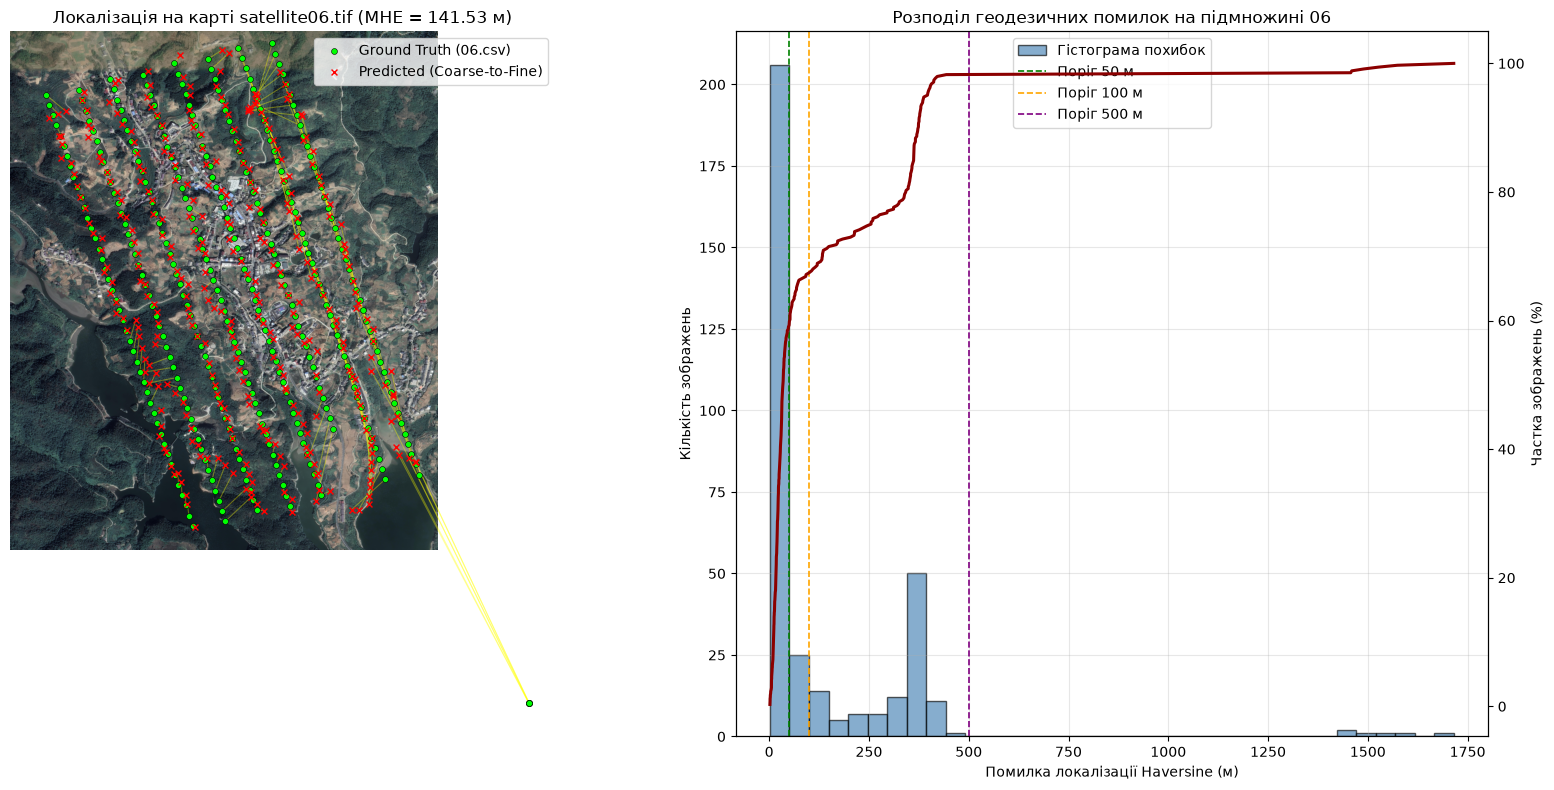

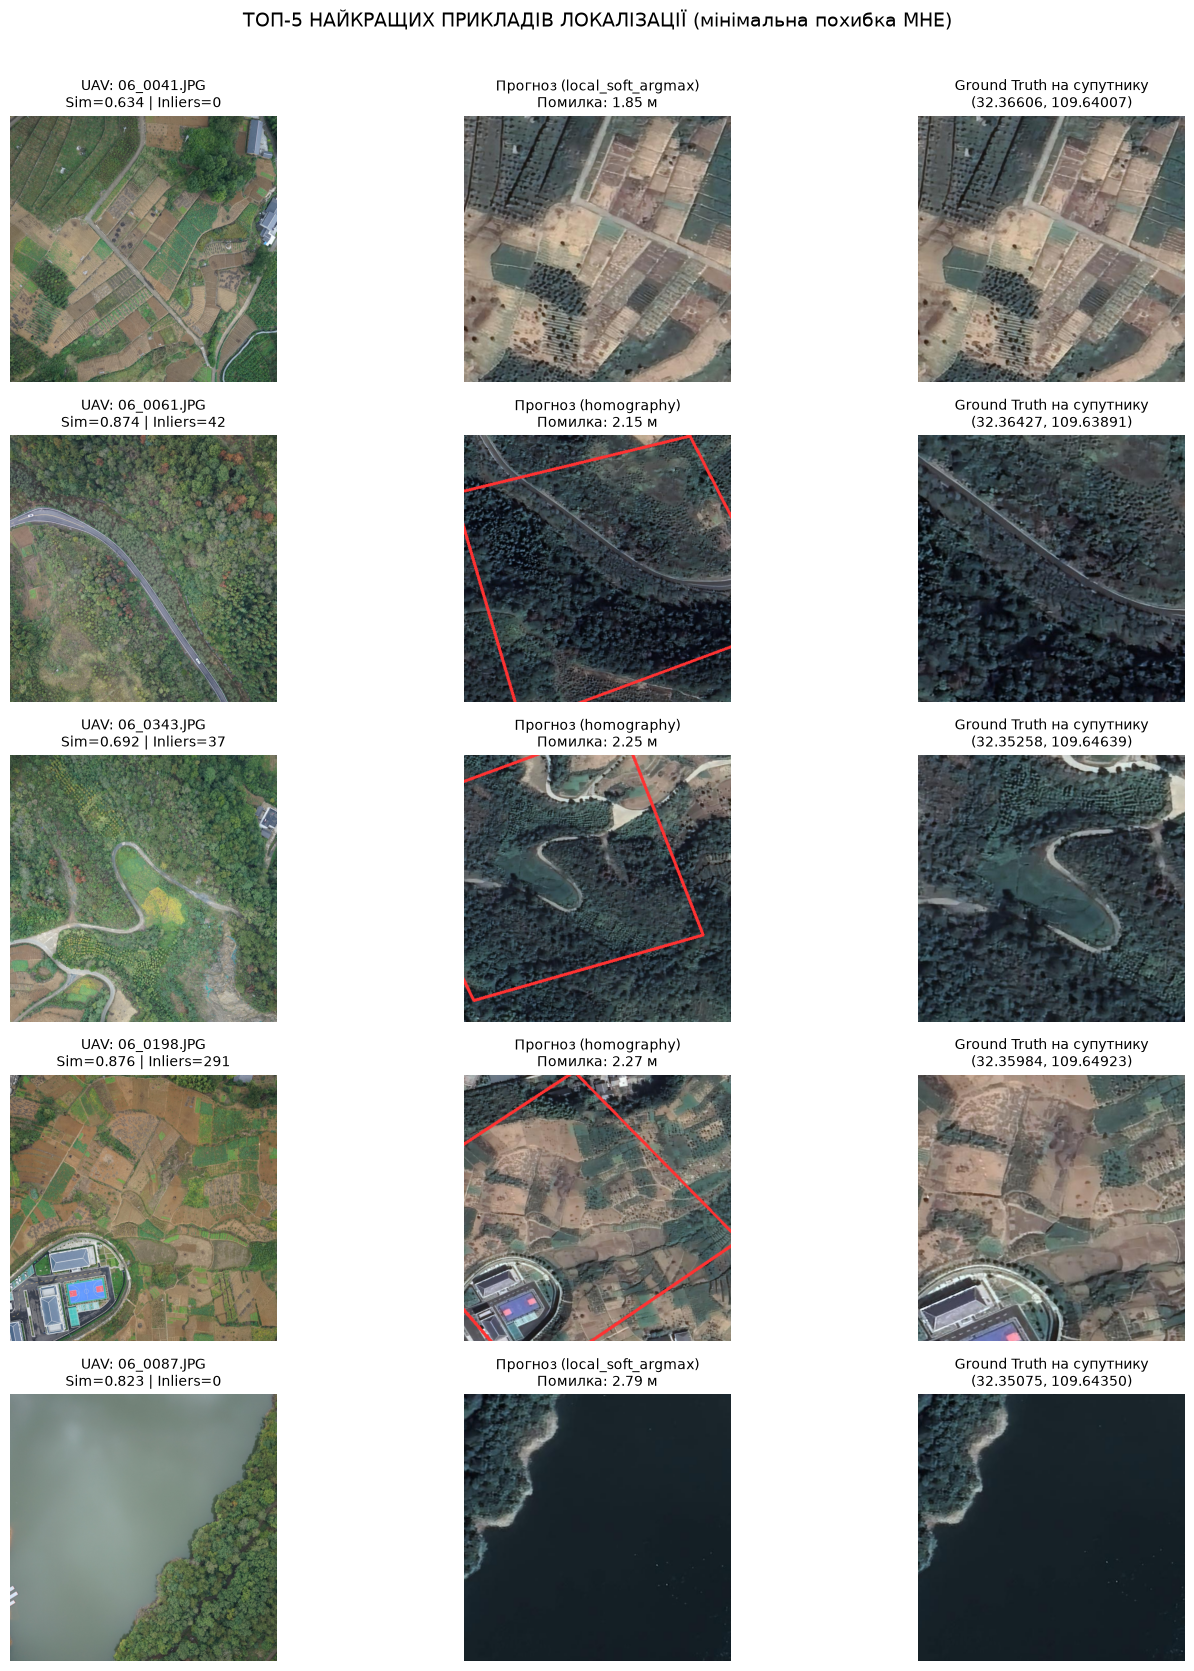

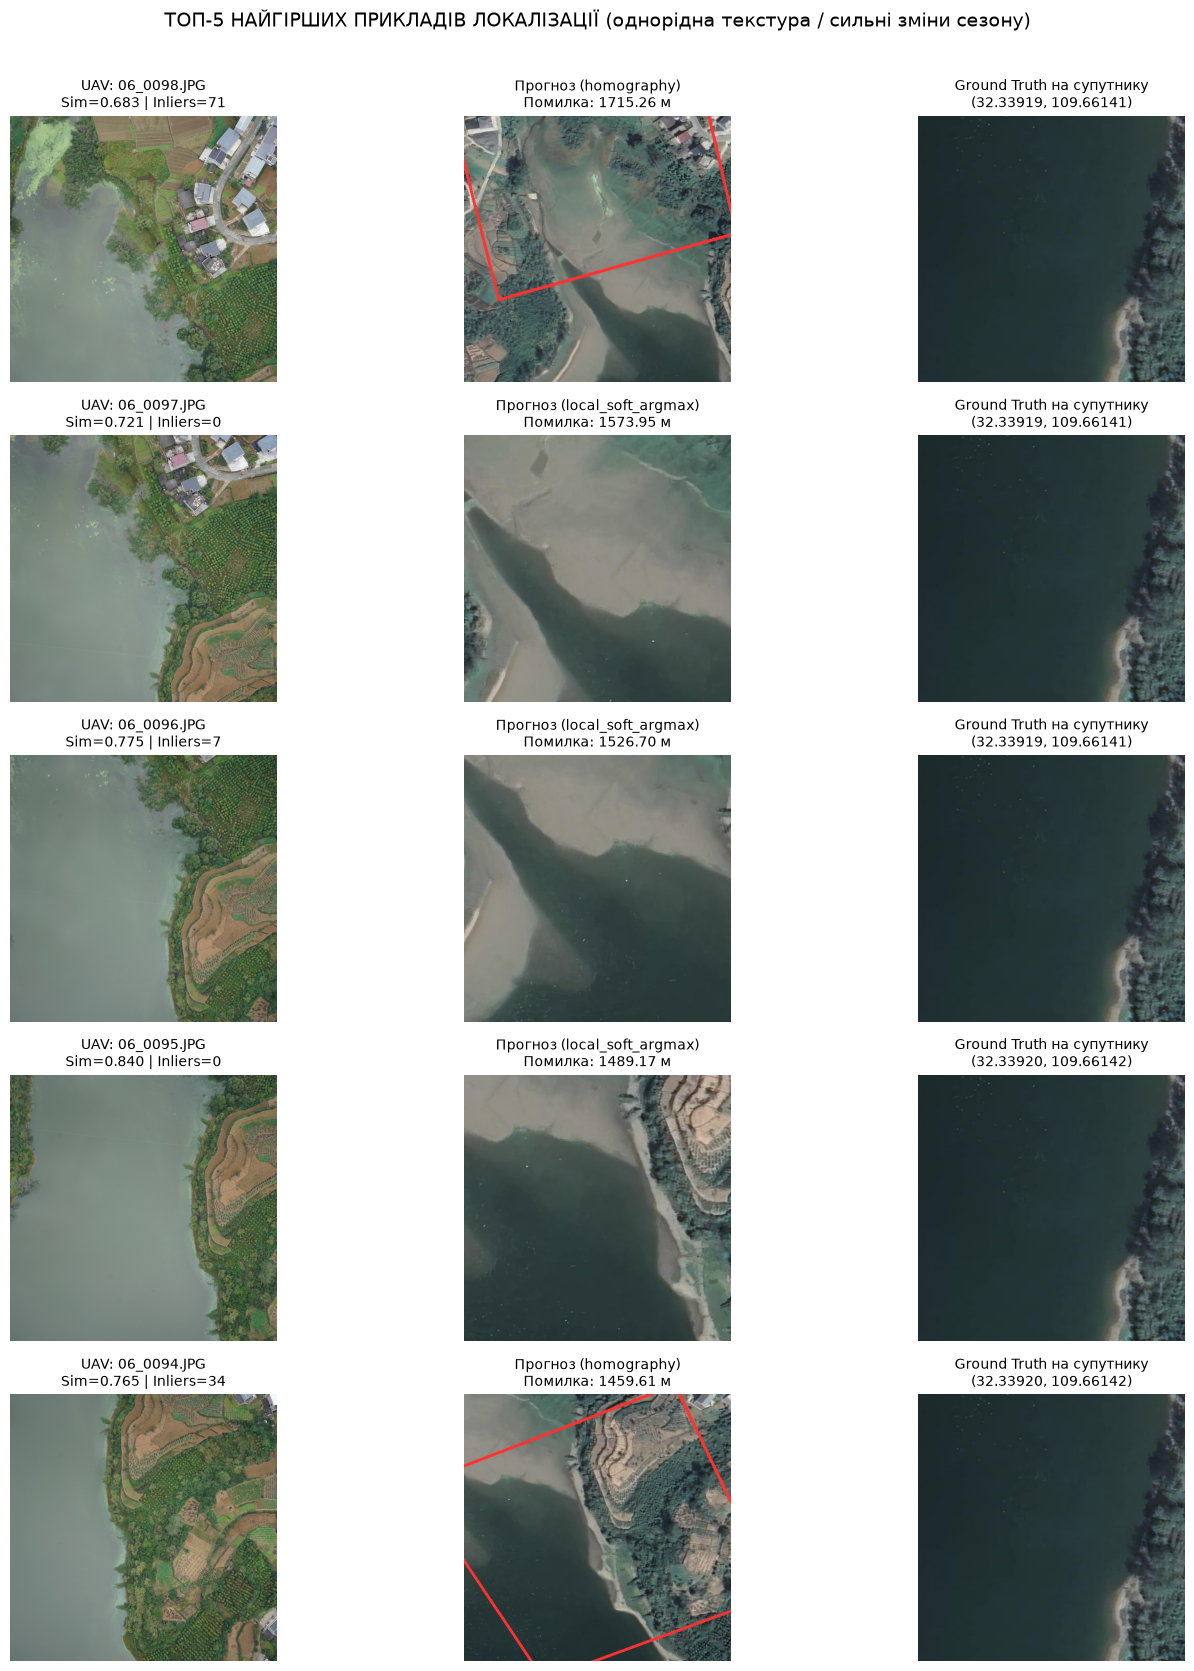

In [14]:
vis_scale = 0.15
sat_small = cv2.resize(sat_img_rgb, (int(SAT_W * vis_scale), int(SAT_H * vis_scale)), interpolation=cv2.INTER_AREA)

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [1.35, 1.0]})

axes[0].imshow(sat_small)
gt_xs = pred_df['gt_x'].values * vis_scale
gt_ys = pred_df['gt_y'].values * vis_scale
pr_xs = pred_df['pred_x'].values * vis_scale
pr_ys = pred_df['pred_y'].values * vis_scale

for gx, gy, px, py in zip(gt_xs, gt_ys, pr_xs, pr_ys):
    axes[0].plot([gx, px], [gy, py], color='yellow', alpha=0.35, linewidth=0.8)

axes[0].scatter(gt_xs, gt_ys, c='lime', s=18, label='Ground Truth (06.csv)', edgecolors='black', linewidths=0.4, zorder=3)
axes[0].scatter(pr_xs, pr_ys, c='red', s=18, marker='x', label='Predicted (Coarse-to-Fine)', linewidths=1.0, zorder=4)
axes[0].set_title(f'Локалізація на карті satellite06.tif (MHE = {metrics_final['Mean Haversine Error (м)']:.2f} м)', fontsize=12)
axes[0].legend(loc='upper right')
axes[0].axis('off')

# Гістограма та кумулятивна функція розподілу (CDF) помилки локалізації
errors_sorted = np.sort(pred_df['error_m'].values)
cdf = np.arange(1, len(errors_sorted) + 1) / len(errors_sorted) * 100.0
axes[1].hist(pred_df['error_m'].values, bins=35, color='steelblue', alpha=0.65, edgecolor='black', label='Гістограма похибок')
ax_cdf = axes[1].twinx()
ax_cdf.plot(errors_sorted, cdf, color='darkred', linewidth=2.2, label='Кумулятивна частка (CDF %)')
for thresh, col in [(50, 'green'), (100, 'orange'), (500, 'purple')]:
    axes[1].axvline(thresh, color=col, linestyle='--', linewidth=1.2, label=f'Поріг {thresh} м')
axes[1].set_xlabel('Помилка локалізації Haversine (м)')
axes[1].set_ylabel('Кількість зображень')
ax_cdf.set_ylabel('Частка зображень (%)')
axes[1].set_title('Розподіл геодезичних помилок на підмножині 06', fontsize=12)
axes[1].legend(loc='upper center')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Візуалізація 5 найкращих та 5 найгірших прикладів локалізації
best_5 = pred_df.nsmallest(5, 'error_m').reset_index(drop=True)
worst_5 = pred_df.nlargest(5, 'error_m').reset_index(drop=True)

def plot_examples_comparison(subset_rows: pd.DataFrame, title_prefix: str) -> None:
    fig, axes = plt.subplots(len(subset_rows), 3, figsize=(15, 3.3 * len(subset_rows)))
    for i, row in subset_rows.iterrows():
        uav_bgr = cv2.imread(str(DRONE_DIR / row['filename']))
        uav_rgb = center_square_crop(cv2.cvtColor(uav_bgr, cv2.COLOR_BGR2RGB))

        half = 256
        px, py = int(row['pred_x']), int(row['pred_y'])
        gx, gy = int(row['gt_x']), int(row['gt_y'])

        px0, py0 = np.clip(px - half, 0, SAT_W - 2 * half), np.clip(py - half, 0, SAT_H - 2 * half)
        gx0, gy0 = np.clip(gx - half, 0, SAT_W - 2 * half), np.clip(gy - half, 0, SAT_H - 2 * half)

        pred_patch = sat_img_rgb[py0:py0 + 2 * half, px0:px0 + 2 * half].copy()
        gt_patch   = sat_img_rgb[gy0:gy0 + 2 * half, gx0:gx0 + 2 * half].copy()

        if row['filename'] in vis_cache:
            vc = vis_cache[row['filename']]
            H = vc['H']
            h_vis, w_vis = vc['sat_patch_vis'].shape[:2]
            corners = np.float32([[0, 0], [w_vis, 0], [w_vis, h_vis], [0, h_vis]]).reshape(-1, 1, 2)
            proj_box = cv2.perspectiveTransform(corners, H)
            pred_patch = vc['sat_patch_vis'].copy()
            cv2.polylines(pred_patch, [np.int32(proj_box)], isClosed=True, color=(255, 50, 50), thickness=3)

        axes[i, 0].imshow(uav_rgb)
        axes[i, 0].set_title(f'UAV: {row['filename']}\nSim={row['top1_similarity']:.3f} | Inliers={int(row['inliers'])}', fontsize=10)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(pred_patch)
        axes[i, 1].set_title(f'Прогноз ({row['method']})\nПомилка: {row['error_m']:.2f} м', fontsize=10)
        axes[i, 1].axis('off')

        axes[i, 2].imshow(gt_patch)
        axes[i, 2].set_title(f'Ground Truth на супутнику\n({row['gt_lat']:.5f}, {row['gt_lon']:.5f})', fontsize=10)
        axes[i, 2].axis('off')

    plt.suptitle(title_prefix, fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()

plot_examples_comparison(best_5, 'ТОП-5 НАЙКРАЩИХ ПРИКЛАДІВ ЛОКАЛІЗАЦІЇ (мінімальна похибка MHE)')
plot_examples_comparison(worst_5, 'ТОП-5 НАЙГІРШИХ ПРИКЛАДІВ ЛОКАЛІЗАЦІЇ (однорідна текстура / сильні зміни сезону)')